In [1]:
import os
import nibabel as nib
import numpy as np
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from lameg.util import get_bigbrain_layer_boundaries, load_meg_sensor_data
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
# from dtw import *
from scipy.signal import correlate

In [2]:
%env SUBJECTS_DIR=/home/common/bonaiuto/auditory_laminar/derivatives/fs/
preproc_data_dir='/home/common/bonaiuto/auditory_laminar/derivatives/processed/'

env: SUBJECTS_DIR=/home/common/bonaiuto/auditory_laminar/derivatives/fs/


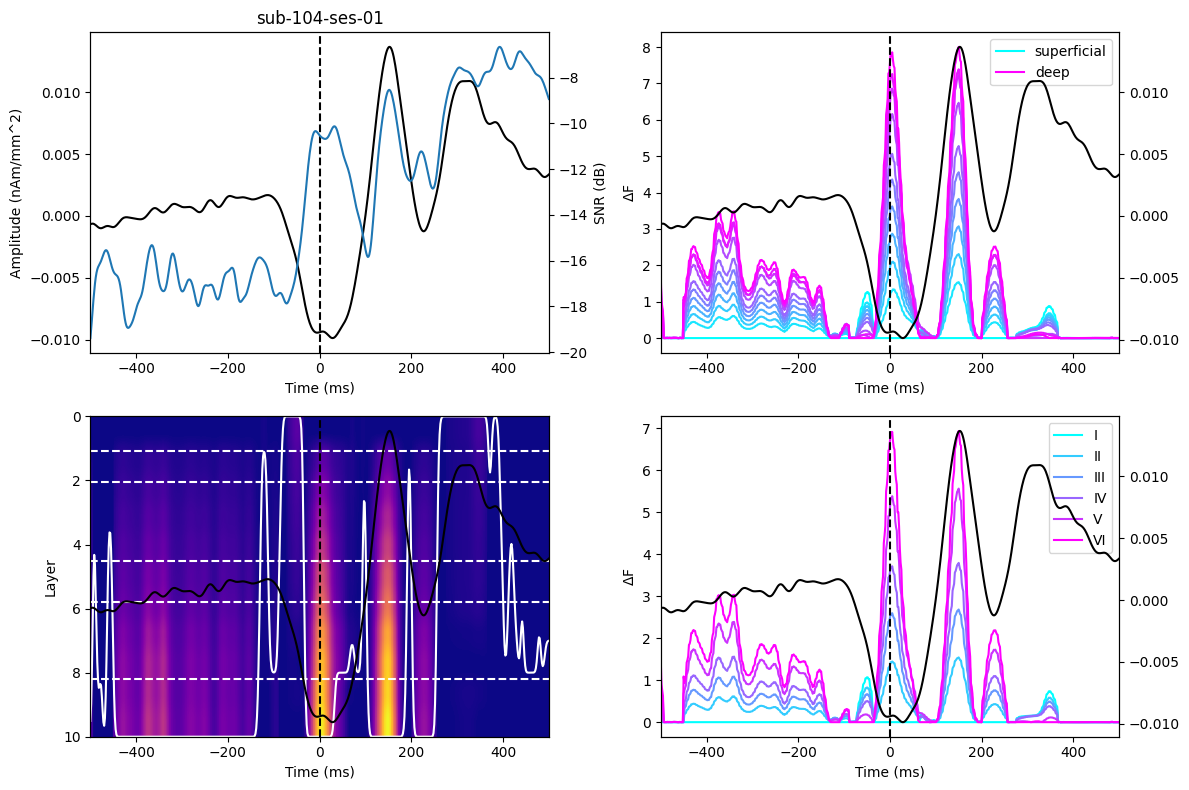

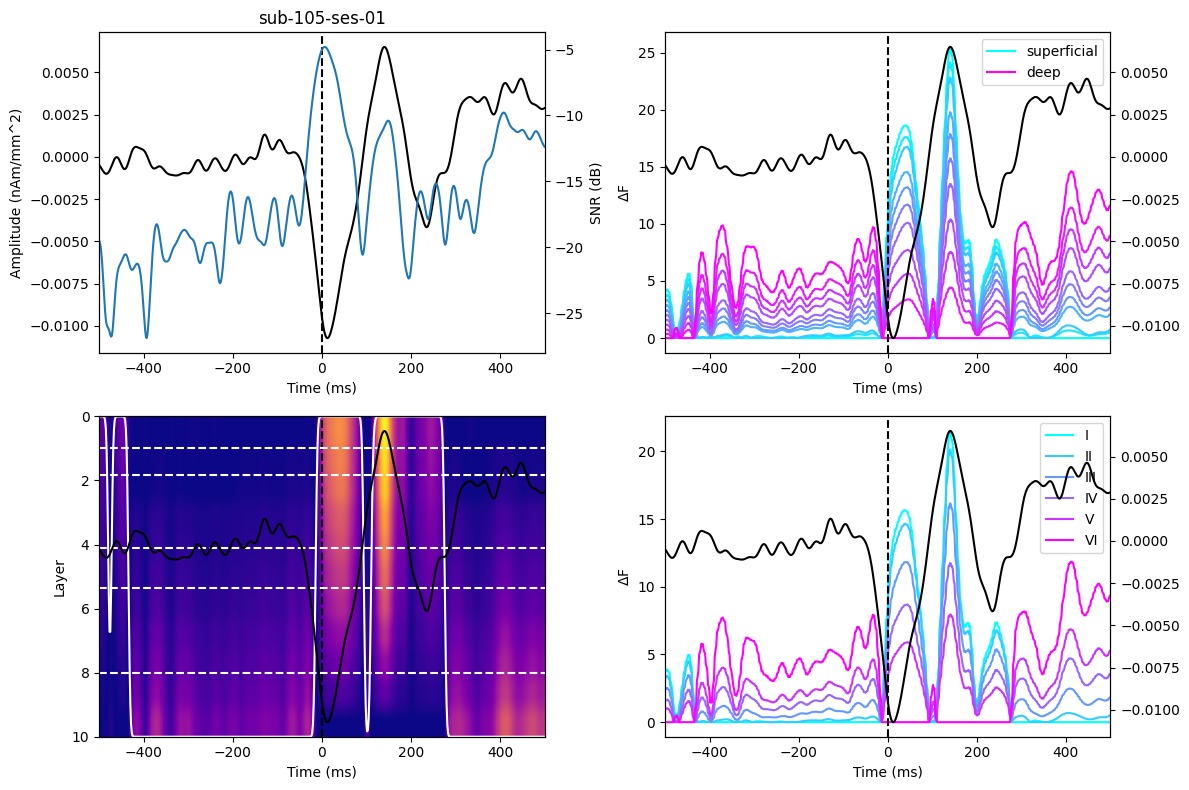

/home/bonaiuto/miniconda3/envs/lameg_test/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
/home/bonaiuto/miniconda3/envs/lameg_test/lib/python3.7/site-packages/numpy/core/_methods.py:182: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


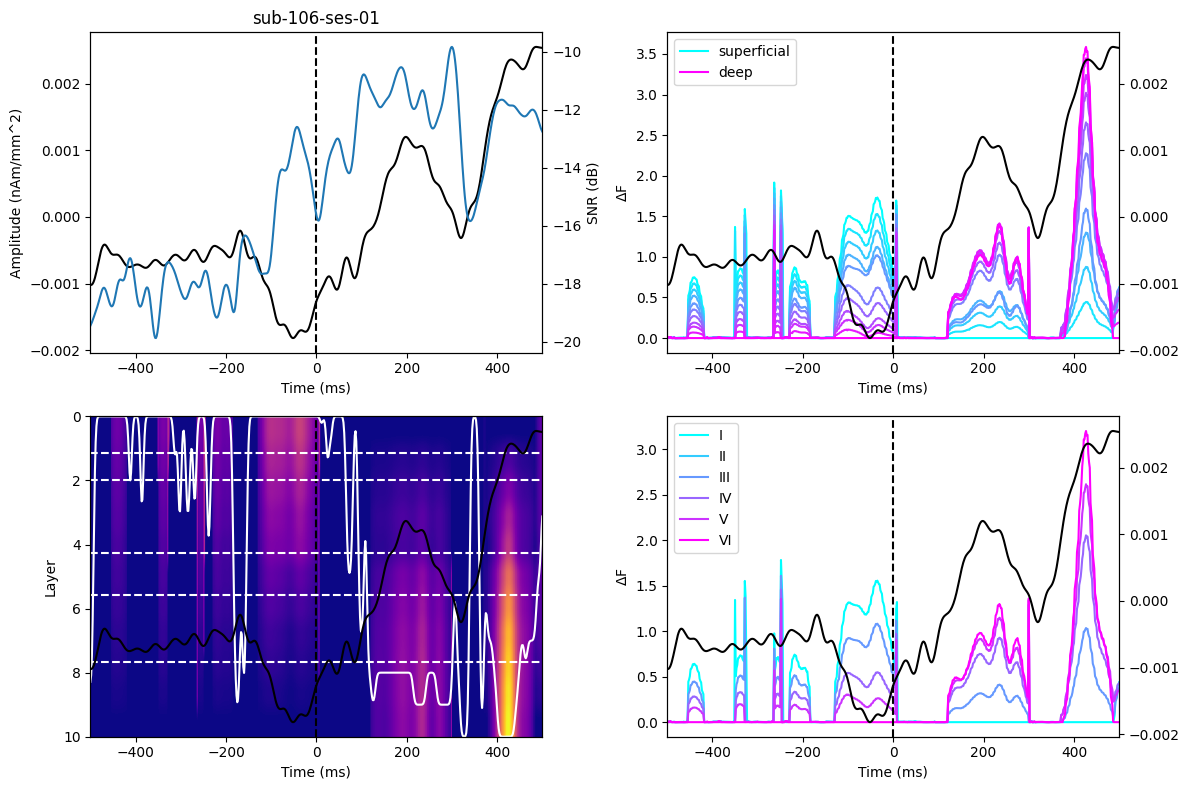

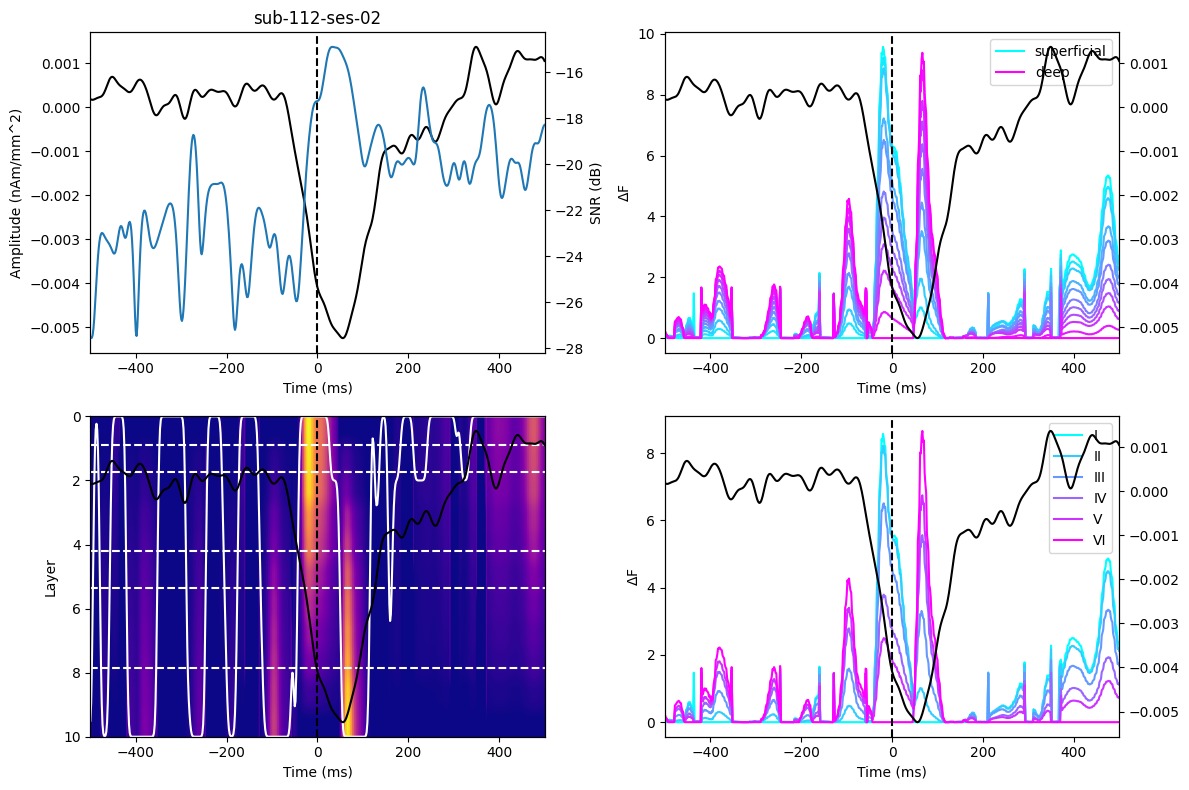

/home/bonaiuto/miniconda3/envs/lameg_test/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
/home/bonaiuto/miniconda3/envs/lameg_test/lib/python3.7/site-packages/numpy/core/_methods.py:182: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


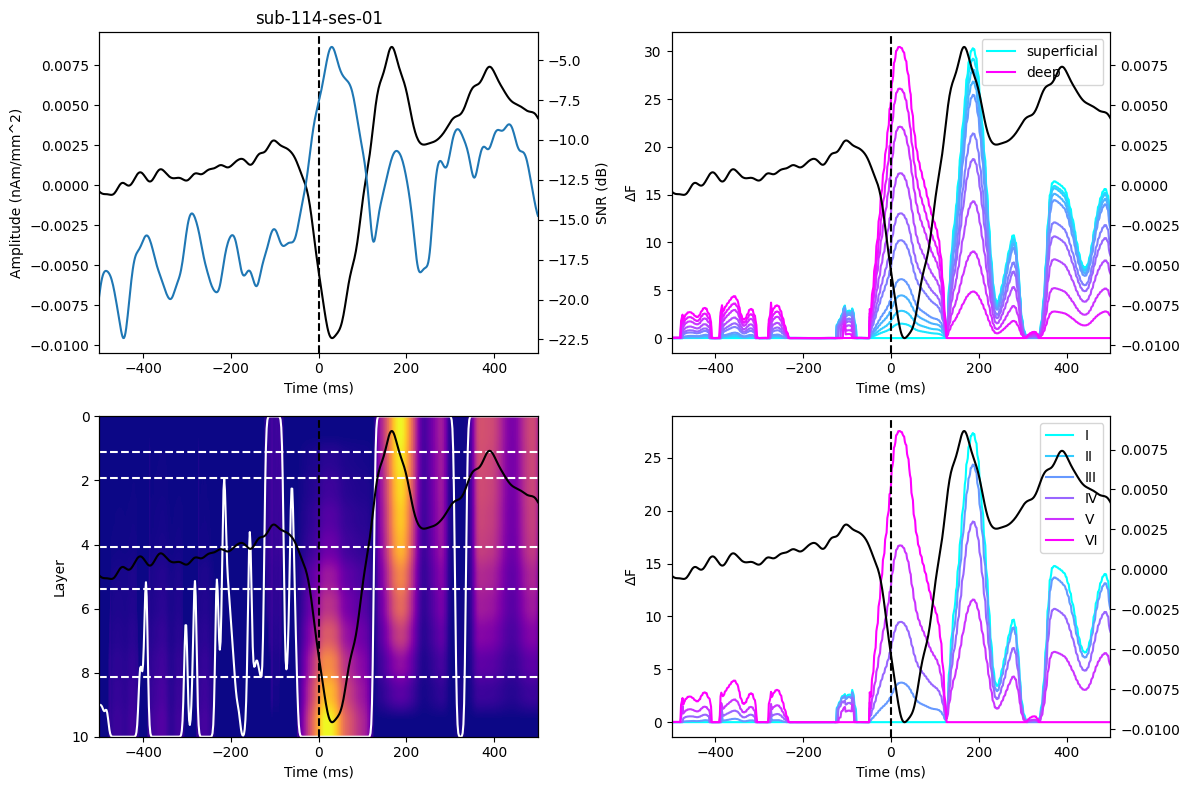

In [3]:
subjects = [
    'sub-104',
    'sub-105',
    'sub-106',
    'sub-112',
    'sub-114'
]
sessions = {
    'sub-104': ['ses-01'],
    'sub-105': ['ses-01'],
    'sub-106': ['ses-01'],
    'sub-112': ['ses-02'],
    'sub-114': ['ses-01']
}
polarity={
    'sub-104': [-1],
    'sub-105': [-1],
    'sub-106': [-1],
    'sub-112': [-1],
    'sub-114': [-1]
}

time_lims=[-500, 500]
n_layers=11
epo_type='btn_trial'
        
out_dir=os.path.join('/home/bonaiuto/auditory_laminar/output',epo_type,'02_mefI/patch_size_5.00mm/')

all_prior_ts=[]
all_F_diff=[]
all_layer_F_diff=[]
all_bb_boundaries=[]
all_snrs=[]

for subject in subjects:
    
    for sess_idx, session in enumerate(sessions[subject]):
        session_polarity=polarity[subject][sess_idx]
        out_fname = os.path.join(out_dir,f'results_{subject}_{session}.npz')
        if os.path.exists(out_fname):
            data_dir=os.path.join(preproc_data_dir,subject,session,'spm')
            orig_data_file = f'spm_autoreject-{subject}-{session}-{epo_type}-epo.mat'
            sensor_data, sensor_time, ch_names = load_meg_sensor_data(os.path.join(data_dir, orig_data_file))
            sensor_time=sensor_time
            st_idx=np.where((sensor_time>=time_lims[0]) & (sensor_time<=time_lims[1]))[0]
            sensor_data=sensor_data[:,st_idx,:]
            sensor_time=sensor_time[st_idx]
            # Compute mean signal across trials (shape: n_channels x n_times)
            mean_signal = np.mean(sensor_data, axis=2)
            # Compute residual noise (trial-by-trial deviations from mean)
            noise = sensor_data - mean_signal[:, :, np.newaxis]
            # Compute RMS of signal and noise over channels
            rms_signal = np.sqrt(np.mean(mean_signal**2, axis=0))  # shape: (n_times,)
            rms_noise = np.sqrt(np.mean(np.mean(noise**2, axis=2), axis=0))  # shape: (n_times,)
            # Compute SNR time series in dB
            snr_db = 20 * np.log10(rms_signal / rms_noise)

            subj_surf_dir=os.path.join(preproc_data_dir,subject,'surf')
            orig_inflated=nib.load(os.path.join(subj_surf_dir, 'inflated.gii'))
            ds_inflated=nib.load(os.path.join(subj_surf_dir, 'inflated.ds.gii'))
            ds_pial = nib.load(os.path.join(subj_surf_dir, 'pial.ds.gii'))

            data = np.load(out_fname, allow_pickle=True)
            prior = data['prior']
            prior_ts = data['prior_ts']
            ts_time = data['ts_time']
            Fs = data['Fs']
            wois = data['wois']

            woi_time=np.mean(wois,axis=-1)
            t_idx=np.where((woi_time>=time_lims[0]) & (woi_time<=time_lims[1]))[0]
            woi_win=woi_time[t_idx]
            Fs_win=Fs[:,t_idx]

            ts_idx=np.where((ts_time>=time_lims[0]) & (ts_time<=time_lims[1]))[0]
            prior_ts=prior_ts[ts_idx]
            ts_time=ts_time[ts_idx]

            # Compute the relative free energy for each layer model, compared to the worst model at each time step
            F_diff = np.zeros((Fs_win.shape[0],Fs_win.shape[1]))
            for t in range(Fs_win.shape[1]):
                minF = np.min(Fs_win[:,t])
                F_diff[:,t] = Fs_win[:,t]-minF
                
            surf_bb_bounds=n_layers*get_bigbrain_layer_boundaries(subject, subj_surf_dir, subj_coord=ds_pial.darrays[0].data[prior,:])
            
            prior_ts = session_polarity*prior_ts

            layers=np.arange(n_layers)
            layer1_idx=np.where((layers<surf_bb_bounds[0]))[0]
            layer2_idx=np.where((layers>=surf_bb_bounds[0]) & (layers<surf_bb_bounds[1]))[0]
            layer3_idx=np.where((layers>=surf_bb_bounds[1]) & (layers<surf_bb_bounds[2]))[0]
            layer4_idx=np.where((layers>=surf_bb_bounds[2]) & (layers<surf_bb_bounds[3]))[0]
            layer5_idx=np.where((layers>=surf_bb_bounds[3]) & (layers<surf_bb_bounds[4]))[0]
            layer6_idx=np.where((layers>=surf_bb_bounds[4]))[0]

            layer_F = np.vstack([
                np.mean(Fs_win[layer1_idx,:],axis=0),
                np.mean(Fs_win[layer2_idx,:],axis=0),
                np.mean(Fs_win[layer3_idx,:],axis=0),
                np.mean(Fs_win[layer4_idx,:],axis=0),
                np.mean(Fs_win[layer5_idx,:],axis=0),
                np.mean(Fs_win[layer6_idx,:],axis=0)
            ])
            layer_F_diff = np.zeros((layer_F.shape[0],layer_F.shape[1]))
            for t in range(layer_F.shape[1]):
                minF = np.nanmin(layer_F[:,t])
                layer_F_diff[:,t] = layer_F[:,t]-minF
            
            col_r = plt.cm.cool(np.linspace(0,1, num=n_layers))
            plt.figure(figsize=(12,8))

            ax=plt.subplot(2,2,1)
            ax.plot(ts_time,prior_ts,'k')
            ax.axvline(x=0, color='k', linestyle='--')
            ax2=ax.twinx()
            ax2.plot(sensor_time, snr_db)
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Amplitude (nAm/mm^2)')
            ax2.set_ylabel('SNR (dB)')
            ax.set_title(f'{subject}-{session}')
            ax.set_xlim(time_lims)

            # Plot relative free energy time series
            ax=plt.subplot(2,2,2)
            for l in range(n_layers):
                if l==0:
                    ax.plot(woi_win, F_diff[l,:], label='superficial', color=col_r[l,:])
                elif l==n_layers-1:
                    ax.plot(woi_win, F_diff[l,:], label='deep', color=col_r[l,:])
                else:
                    ax.plot(woi_win, F_diff[l,:], color=col_r[l,:])
            plt.legend()
            ax.axvline(x=0, color='k', linestyle='--')
            ax2=ax.twinx()
            ax2.plot(ts_time,prior_ts,'k')
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel(r'$\Delta$F')
            ax.set_xlim(time_lims)

            ax=plt.subplot(2,2,3)
            h=ax.imshow(F_diff,aspect='auto', extent=[woi_win[0], woi_win[-1], n_layers-1,0],cmap='plasma',origin='upper')
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Layer')
            peak_layer=gaussian_filter1d(np.argmax(F_diff,axis=0).astype(float), 2)
            ax.plot(woi_win, peak_layer, 'w')
            ax.axvline(x=0, color='k', linestyle='--')
            for i in range(len(surf_bb_bounds)-1):
                ax.axhline(y=surf_bb_bounds[i],color='w',linestyle='--')        
    #         col_r=plt.colorbar(h)
    #         col_r.set_label(r'$\Delta$F')
            ax2=ax.twinx()
            ax2.plot(ts_time,prior_ts,'k')
            ax2.set_yticks([])

            ax=plt.subplot(2,2,4)
            col_l = plt.cm.cool(np.linspace(0,1, num=6))
            l_labels=['I','II','III','IV','V','VI']
            for i in range(6):
                ax.plot(woi_win, layer_F_diff[i,:],label=l_labels[i],color=col_l[i])
            plt.legend()
            ax.axvline(x=0, color='k', linestyle='--')
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel(r'$\Delta$F')
            ax2=ax.twinx()
            ax2.plot(ts_time,prior_ts,'k')
            ax.set_xlim(time_lims)

            plt.tight_layout()
            plt.show()

            all_snrs.append(snr_db)
            all_prior_ts.append(prior_ts)
            all_F_diff.append(F_diff)
            all_layer_F_diff.append(layer_F_diff)
            all_bb_boundaries.append(surf_bb_bounds)
            
all_snrs=np.array(all_snrs)
all_prior_ts=np.array(all_prior_ts)
all_F_diff=np.array(all_F_diff)
all_layer_F_diff=np.array(all_layer_F_diff)
all_bb_boundaries=np.array(all_bb_boundaries)

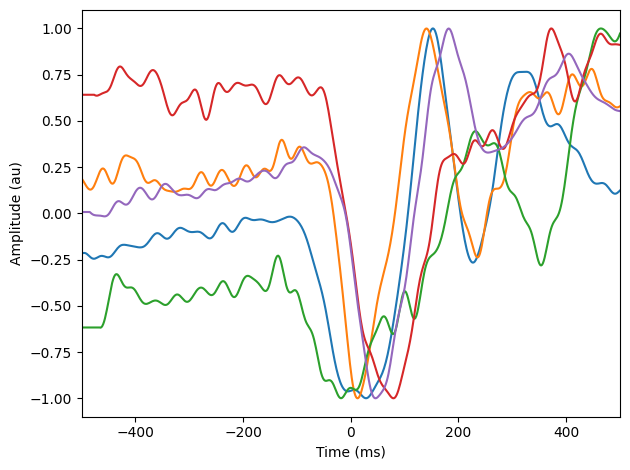

In [4]:
# def minmax_unit(x):
#     return 2 * (x - np.min(x)) / (np.max(x) - np.min(x)) - 1
# norm_1 = minmax_unit(all_prior_ts[0, :])

# plt.figure()
# plt.plot(ts_time, all_prior_ts[0, :], label=subjects[0])

# align_idx = []
# aligned_snrs = []
# aligned_prior_ts = []
# aligned_F_diff = []
# aligned_layer_F_diff = []

# for ss_idx in range(all_prior_ts.shape[0]):

#     if ss_idx == 0:
#         aligned_idx=np.arange(all_prior_ts.shape[1])
#         align_idx.append(aligned_idx)
#     else:
#         norm_2 = minmax_unit(all_prior_ts[ss_idx, :])
#         alignment = dtw(norm_2, norm_1, keep_internals=True,
#                         step_pattern=rabinerJuangStepPattern(5, "c"))
#         aligned_idx = warp(alignment, index_reference=False)
#         align_idx.append(aligned_idx)
#         plt.plot(ts_time, all_prior_ts[ss_idx,aligned_idx]/np.max(np.abs(all_prior_ts[ss_idx,aligned_idx])), label=subject)

#     aligned_snrs.append(all_snrs[ss_idx, aligned_idx])
#     aligned_prior_ts.append(all_prior_ts[ss_idx, aligned_idx])
#     aligned_F_diff.append(all_F_diff[ss_idx, :, aligned_idx])
#     aligned_layer_F_diff.append(all_layer_F_diff[ss_idx, :, aligned_idx])

# aligned_snrs = np.array(aligned_snrs)
# aligned_prior_ts = np.array(aligned_prior_ts)
# aligned_F_diff = np.array(aligned_F_diff)
# aligned_F_diff = np.transpose(aligned_F_diff, (0, 2, 1))
# aligned_layer_F_diff = np.array(aligned_layer_F_diff)
# aligned_layer_F_diff = np.transpose(aligned_layer_F_diff, (0, 2, 1))


# plt.xlabel("Time (ms)")
# plt.ylabel('Amplitude (au)')
# plt.tight_layout()
# plt.xlim(time_lims)
# plt.show()

# ---------- Woody alignment utilities ----------
def minmax_unit(x):
    x = np.asarray(x)
    xmin, xmax = np.min(x), np.max(x)
    if xmax == xmin:
        return np.zeros_like(x)
    return 2 * (x - xmin) / (xmax - xmin) - 1

def _best_lag(x, y, max_lag=None):
    n = len(x)
    if max_lag is None:
        max_lag = n // 4
    c = correlate(y, x, mode='full')
    lags = np.arange(-n + 1, n)
    sel = (lags >= -max_lag) & (lags <= max_lag)
    lag_win = lags[sel]
    return lag_win[np.argmax(c[sel])]

def woody_align_indices(X, ref_idx=0, max_lag=1000, n_iter=1000):
    """
    X: (n_series, n_time)
    ref_idx: index of the reference series (default: 0)
    Returns:
        lags:      (n_series,) integer sample lags relative to reference
        align_idx: list of index arrays for each series
        template:  final alignment template
    """
    X = np.asarray(X)
    n_series, n_time = X.shape
    template = minmax_unit(X[ref_idx])
    lags = np.zeros(n_series, dtype=int)

    for _ in range(max(n_iter, 1)):
        for i in range(n_series):
            xi = minmax_unit(X[i])
            lags[i] = _best_lag(xi, template, max_lag=max_lag)

        aligned_stack = []
        for i in range(n_series):
            idx = np.clip(np.arange(n_time) + lags[i], 0, n_time - 1)
            aligned_stack.append(X[i, idx])
        template = minmax_unit(np.nanmean(np.vstack(aligned_stack), axis=0))

    align_idx = [np.clip(np.arange(n_time) + l, 0, n_time - 1) for l in lags]
    return lags, align_idx, template

# ---------- Apply Woody alignment ----------
# all_prior_ts: (n_subjects*n_sessions, n_time)
# first row = first session of first subject = reference

ref_idx = 0
plt.figure()
plt.plot(ts_time, minmax_unit(all_prior_ts[ref_idx, :]))  # reference trace

lags, align_idx, woody_template = woody_align_indices(
    all_prior_ts, ref_idx=ref_idx, max_lag=50, n_iter=3
)

aligned_snrs = []
aligned_prior_ts = []
aligned_F_diff = []
aligned_layer_F_diff = []

for ss_idx in range(all_prior_ts.shape[0]):
    aligned_idx = align_idx[ss_idx]

    if ss_idx > 0:
        plt.plot(
            ts_time,
            minmax_unit(all_prior_ts[ss_idx, aligned_idx])
        )

    aligned_snrs.append(all_snrs[ss_idx, aligned_idx])
    aligned_prior_ts.append(all_prior_ts[ss_idx, aligned_idx])
    aligned_F_diff.append(all_F_diff[ss_idx, :, aligned_idx])
    aligned_layer_F_diff.append(all_layer_F_diff[ss_idx, :, aligned_idx])

aligned_snrs = np.array(aligned_snrs)
aligned_prior_ts = np.array(aligned_prior_ts)
aligned_F_diff = np.transpose(np.array(aligned_F_diff), (0, 2, 1))
aligned_layer_F_diff = np.transpose(np.array(aligned_layer_F_diff), (0, 2, 1))

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (au)")
plt.tight_layout()
plt.xlim(time_lims)
plt.show()


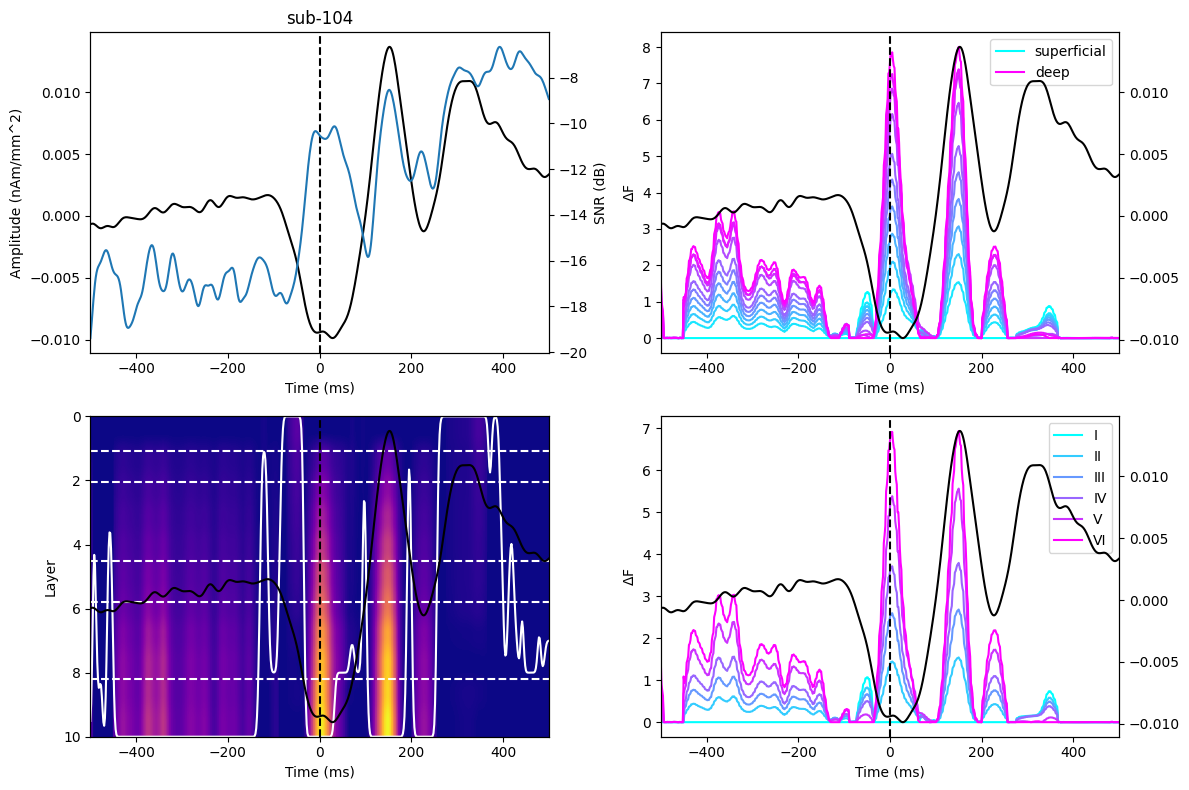

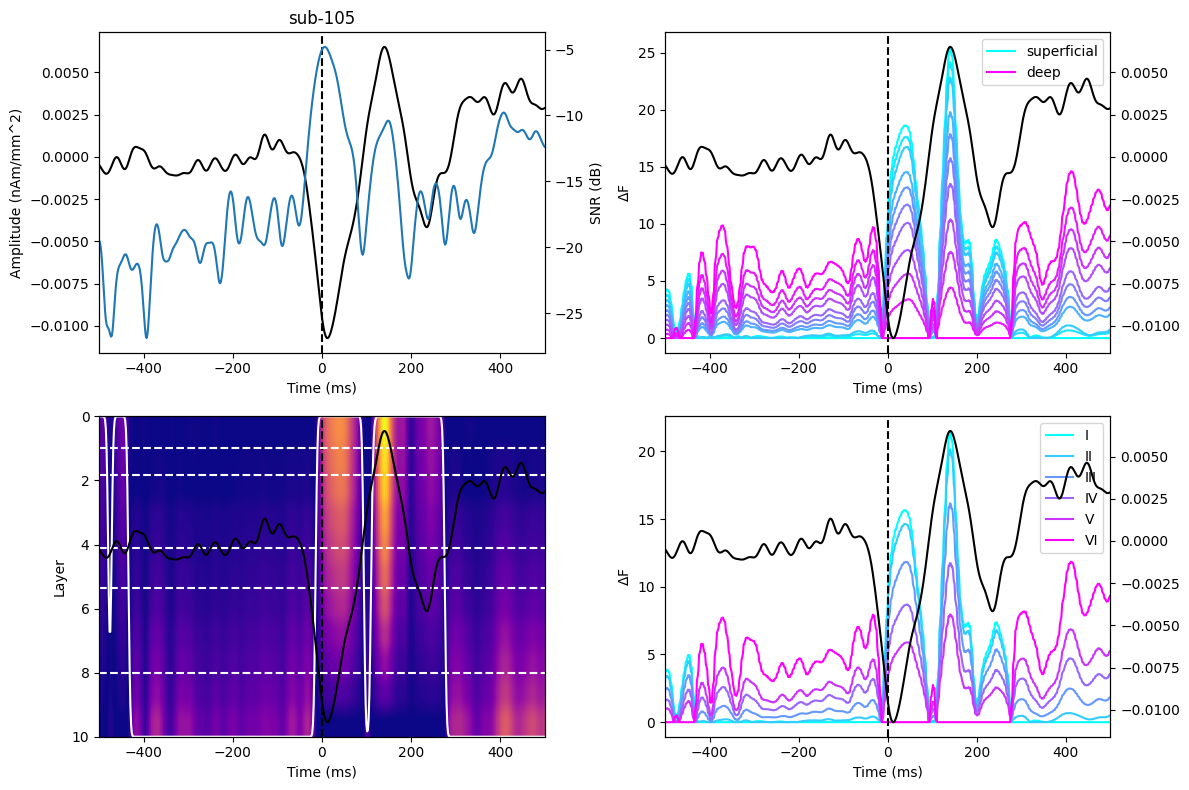

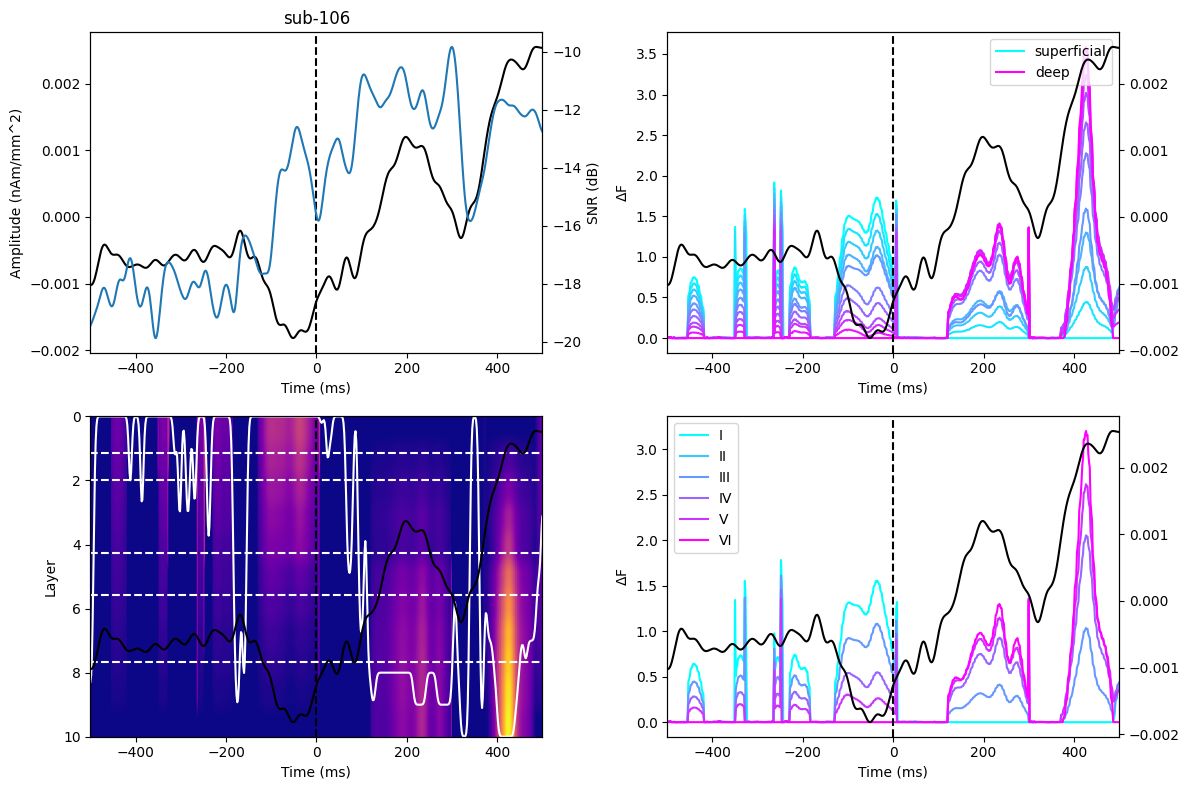

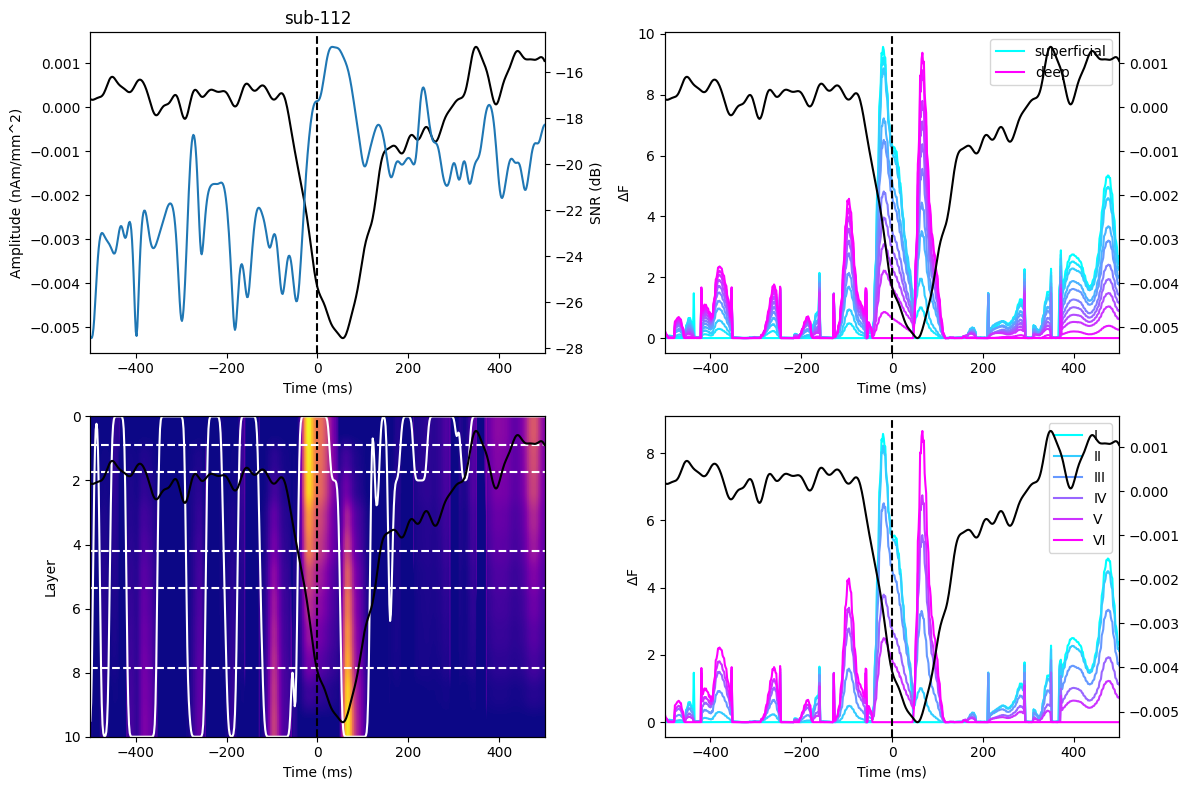

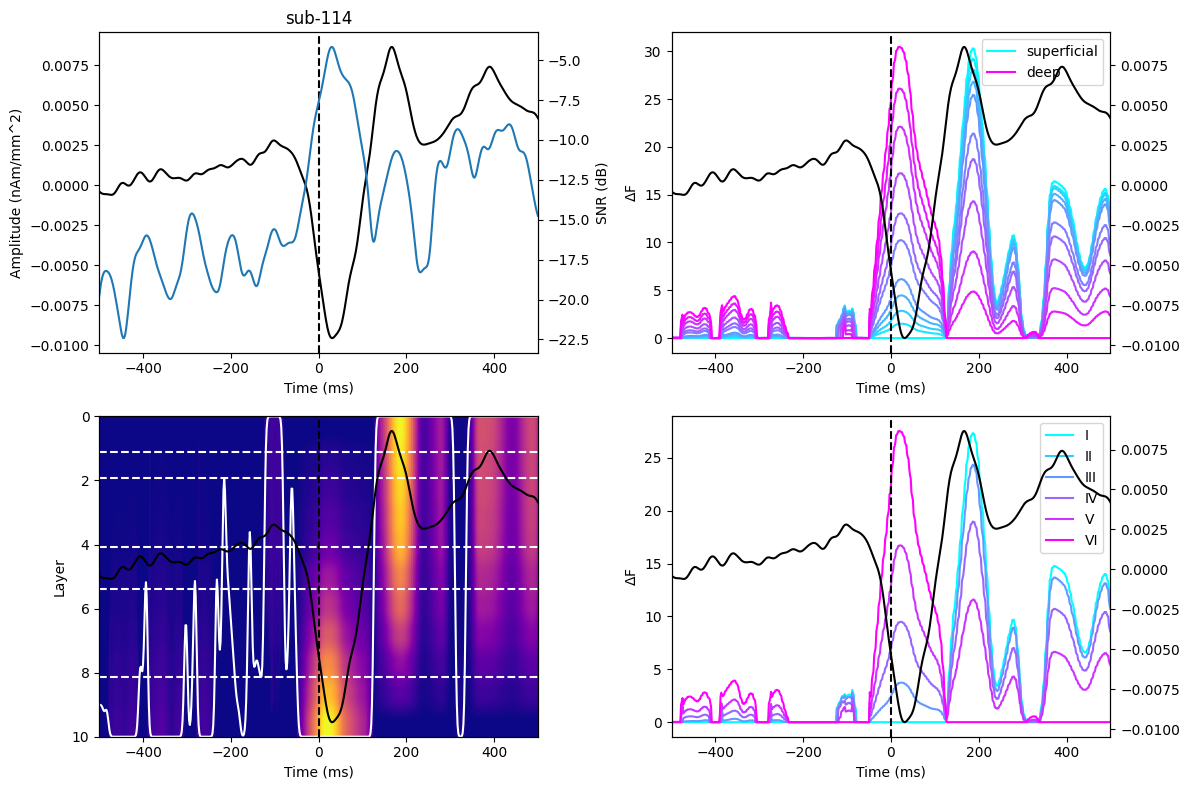

In [5]:
subjects_m_snrs = []
subjects_m_prior_ts = []
subjects_m_F_diff = []
subjects_m_layer_F_diff = []
subjects_m_bb_boundaries = []

for s_idx, subject in enumerate(subjects):
    if s_idx<all_snrs.shape[0]:
        subj_m_snrs = all_snrs[s_idx,:]
        subj_m_prior_ts = all_prior_ts[s_idx,:]
        subj_m_F_diff = all_F_diff[s_idx,:,:]
        subj_m_layer_F_diff = all_layer_F_diff[s_idx,:,:]
        subj_m_bb_boundaries = all_bb_boundaries[s_idx,:]

        subjects_m_snrs.append(subj_m_snrs)
        subjects_m_prior_ts.append(subj_m_prior_ts)
        subjects_m_F_diff.append(subj_m_F_diff)
        subjects_m_layer_F_diff.append(subj_m_layer_F_diff)
        subjects_m_bb_boundaries.append(subj_m_bb_boundaries)

        col_r = plt.cm.cool(np.linspace(0,1, num=n_layers))
        fig=plt.figure(figsize=(12,8))

        ax=plt.subplot(2,2,1)
        ax.plot(ts_time,subj_m_prior_ts,'k')
        ax.axvline(x=0, color='k', linestyle='--')
        ax2=ax.twinx()
        ax2.plot(sensor_time, subj_m_snrs)
        ax.set_ylabel('Amplitude (nAm/mm^2)')
        ax2.set_ylabel('SNR (dB)')
        ax.set_xlabel('Time (ms)')
        ax.set_title(subject)
        ax.set_xlim(time_lims)

        # Plot relative free energy time series
        ax=plt.subplot(2,2,2)
        for l in range(n_layers):
            if l==0:
                ax.plot(woi_win, subj_m_F_diff[l,:], label='superficial', color=col_r[l,:])
            elif l==n_layers-1:
                ax.plot(woi_win, subj_m_F_diff[l,:], label='deep', color=col_r[l,:])
            else:
                ax.plot(woi_win, subj_m_F_diff[l,:], color=col_r[l,:])
        ax.axvline(x=0, color='k', linestyle='--')
        plt.legend(loc='upper right')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel(r'$\Delta$F')
        ax.set_xlim(time_lims)

        ax=plt.subplot(2,2,3)
        h=ax.imshow(subj_m_F_diff,aspect='auto', extent=[woi_win[0], woi_win[-1], n_layers-1,0],cmap='plasma',origin='upper')
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Layer')
        peak_layer=gaussian_filter1d(np.argmax(subj_m_F_diff,axis=0).astype(float), 2)
        ax.plot(woi_win, peak_layer, 'w')
        ax.axvline(x=0, color='k', linestyle='--')
        for i in range(len(subj_m_bb_boundaries)-1):
            ax.axhline(y=subj_m_bb_boundaries[i],color='w',linestyle='--')        
        # col_r=plt.colorbar(h)
        # col_r.set_label(r'$\Delta$F')
        # divider = make_axes_locatable(ax)
        # cax = divider.append_axes("right", size="5%", pad=0.1)
        # cbar = fig.colorbar(h, cax=cax, label=r'$\Delta$F')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax2.set_yticks([])

        ax=plt.subplot(2,2,4)
        col_l = plt.cm.cool(np.linspace(0,1, num=6))
        l_labels=['I','II','III','IV','V','VI']
        for i in range(6):
            ax.plot(woi_win, subj_m_layer_F_diff[i,:],label=l_labels[i],color=col_l[i])
        ax.axvline(x=0, color='k', linestyle='--')
        plt.legend()
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel(r'$\Delta$F')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax.set_xlim(time_lims)

        plt.tight_layout()
    
subjects_m_snrs = np.array(subjects_m_snrs)
subjects_m_prior_ts = np.array(subjects_m_prior_ts)
subjects_m_F_diff = np.array(subjects_m_F_diff)
subjects_m_layer_F_diff = np.array(subjects_m_layer_F_diff)
subjects_m_bb_boundaries = np.array(subjects_m_bb_boundaries)

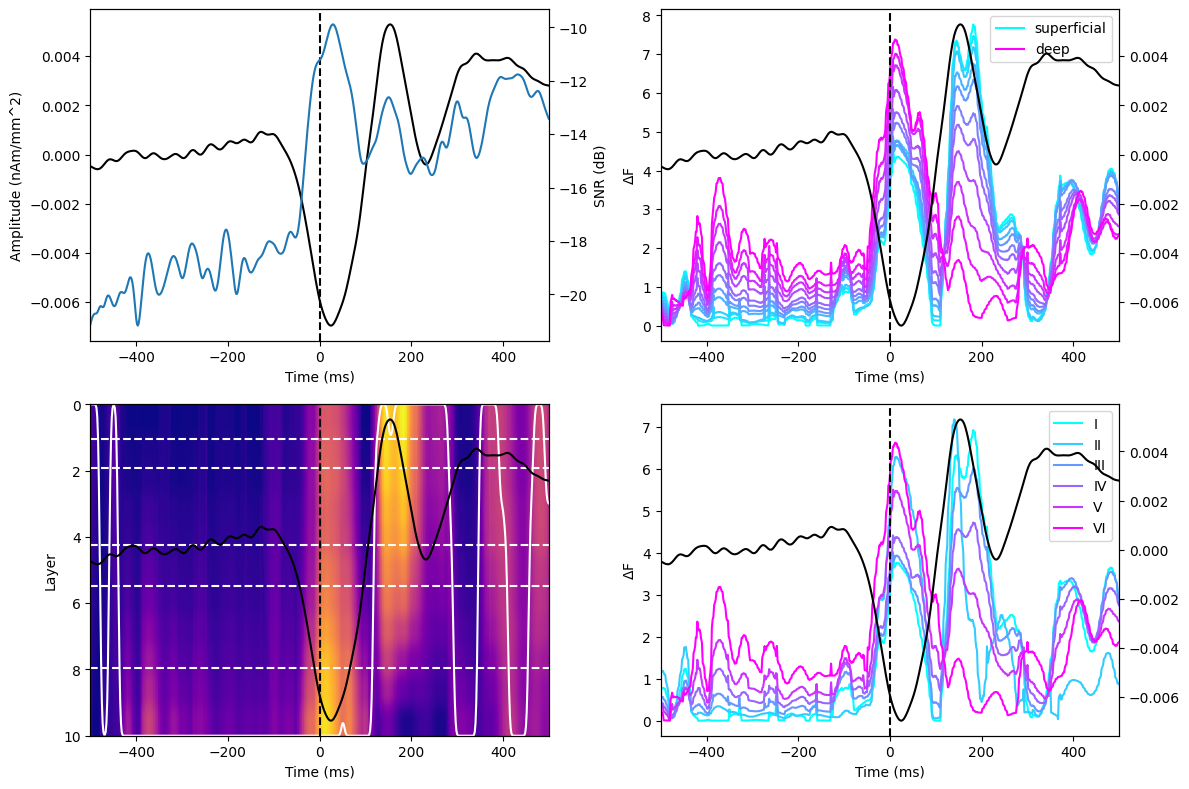

In [6]:
m_snrs=np.mean(subjects_m_snrs,axis=0)
m_prior_ts=np.mean(subjects_m_prior_ts,axis=0)
m_F_diff=np.mean(subjects_m_F_diff,axis=0)
m_layer_F_diff=np.nanmean(subjects_m_layer_F_diff,axis=0)
m_bb_boundaries=np.mean(subjects_m_bb_boundaries,axis=0)

col_r = plt.cm.cool(np.linspace(0,1, num=n_layers))
fig=plt.figure(figsize=(12,8))

ax=plt.subplot(2,2,1)
ax.plot(ts_time,m_prior_ts,'k')
ax.axvline(x=0, color='k', linestyle='--')
ax2=ax.twinx()
ax2.plot(sensor_time, m_snrs)
ax.set_ylabel('Amplitude (nAm/mm^2)')
ax2.set_ylabel('SNR (dB)')
ax.set_xlabel('Time (ms)')
ax.set_xlim(time_lims)

# Plot relative free energy time series
ax=plt.subplot(2,2,2)
for l in range(n_layers):
    if l==0:
        ax.plot(woi_win, m_F_diff[l,:], label='superficial', color=col_r[l,:])
    elif l==n_layers-1:
        ax.plot(woi_win, m_F_diff[l,:], label='deep', color=col_r[l,:])
    else:
        ax.plot(woi_win, m_F_diff[l,:], color=col_r[l,:])
ax.axvline(x=0, color='k', linestyle='--')
plt.legend(loc='upper right')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax.set_xlabel('Time (ms)')
ax.set_ylabel(r'$\Delta$F')
ax.set_xlim(time_lims)

ax=plt.subplot(2,2,3)
h=ax.imshow(m_F_diff,aspect='auto', extent=[woi_win[0], woi_win[-1], n_layers-1,0],cmap='plasma',origin='upper')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Layer')
peak_layer=gaussian_filter1d(np.argmax(m_F_diff,axis=0).astype(float), 2)
ax.plot(woi_win, peak_layer, 'w')
ax.axvline(x=0, color='k', linestyle='--')
for i in range(len(m_bb_boundaries)-1):
    ax.axhline(y=m_bb_boundaries[i],color='w',linestyle='--')        
# col_r=plt.colorbar(h)
# col_r.set_label(r'$\Delta$F')
# divider = make_axes_locatable(ax)
# cax = divider.append_axes("right", size="5%", pad=0.1)
# cbar = fig.colorbar(h, cax=cax, label=r'$\Delta$F')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax2.set_yticks([])

ax=plt.subplot(2,2,4)
col_l = plt.cm.cool(np.linspace(0,1, num=6))
l_labels=['I','II','III','IV','V','VI']
for i in range(6):
    ax.plot(woi_win, m_layer_F_diff[i,:],label=l_labels[i],color=col_l[i])
ax.axvline(x=0, color='k', linestyle='--')
plt.legend()
ax.set_xlabel('Time (ms)')
ax.set_ylabel(r'$\Delta$F')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax.set_xlim(time_lims)

plt.tight_layout()
# plt.savefig('../figures/btn_trial_epoch_mean_rel_to_worst.pdf')

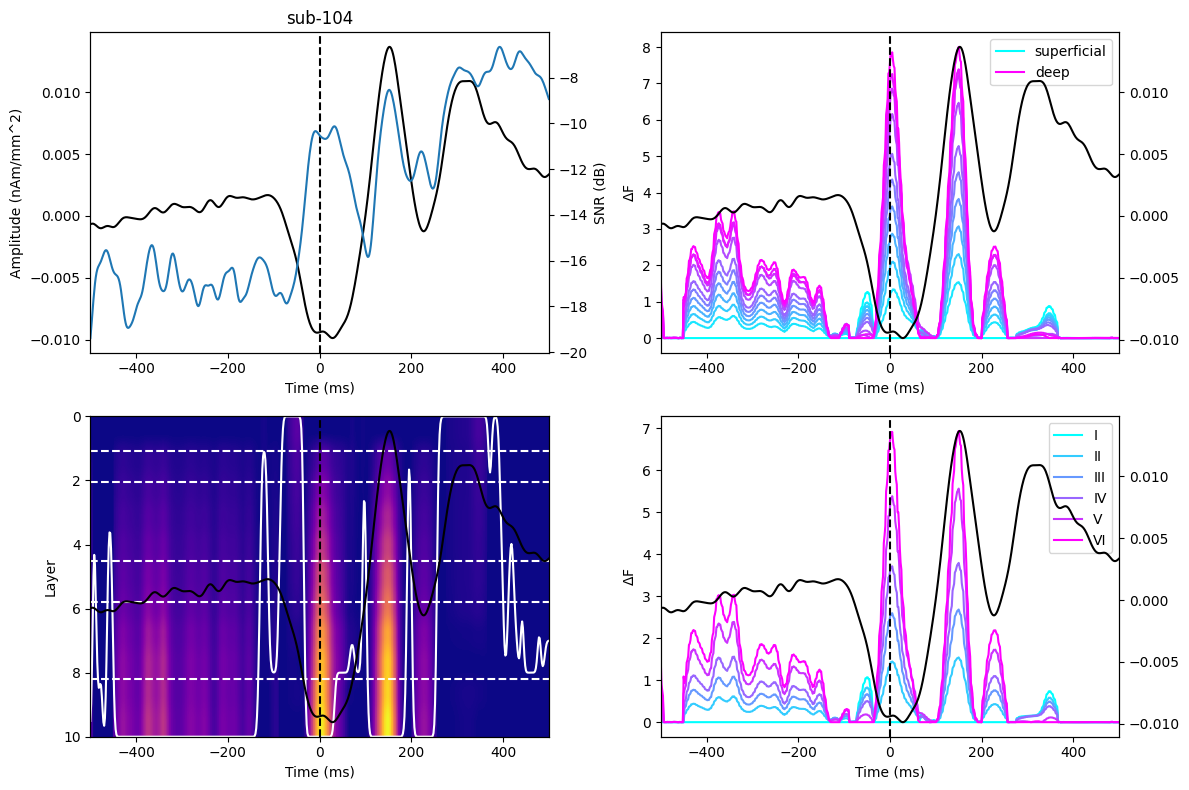

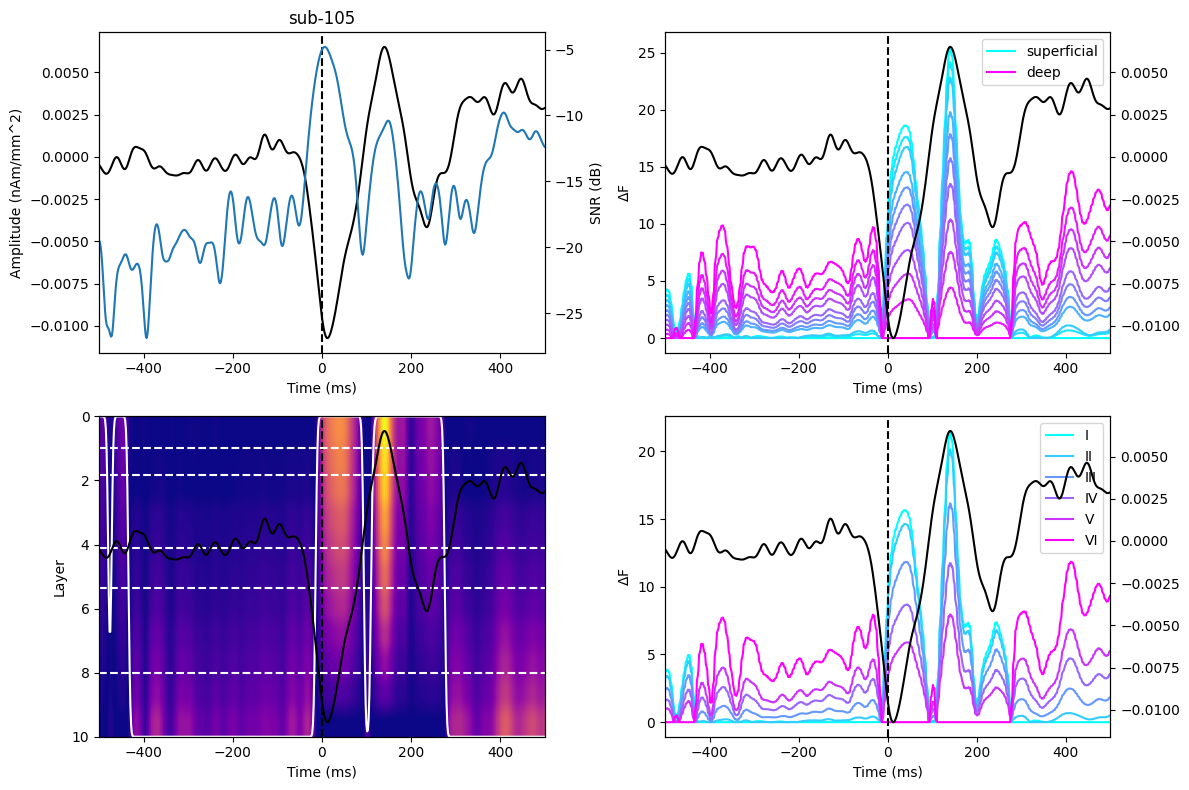

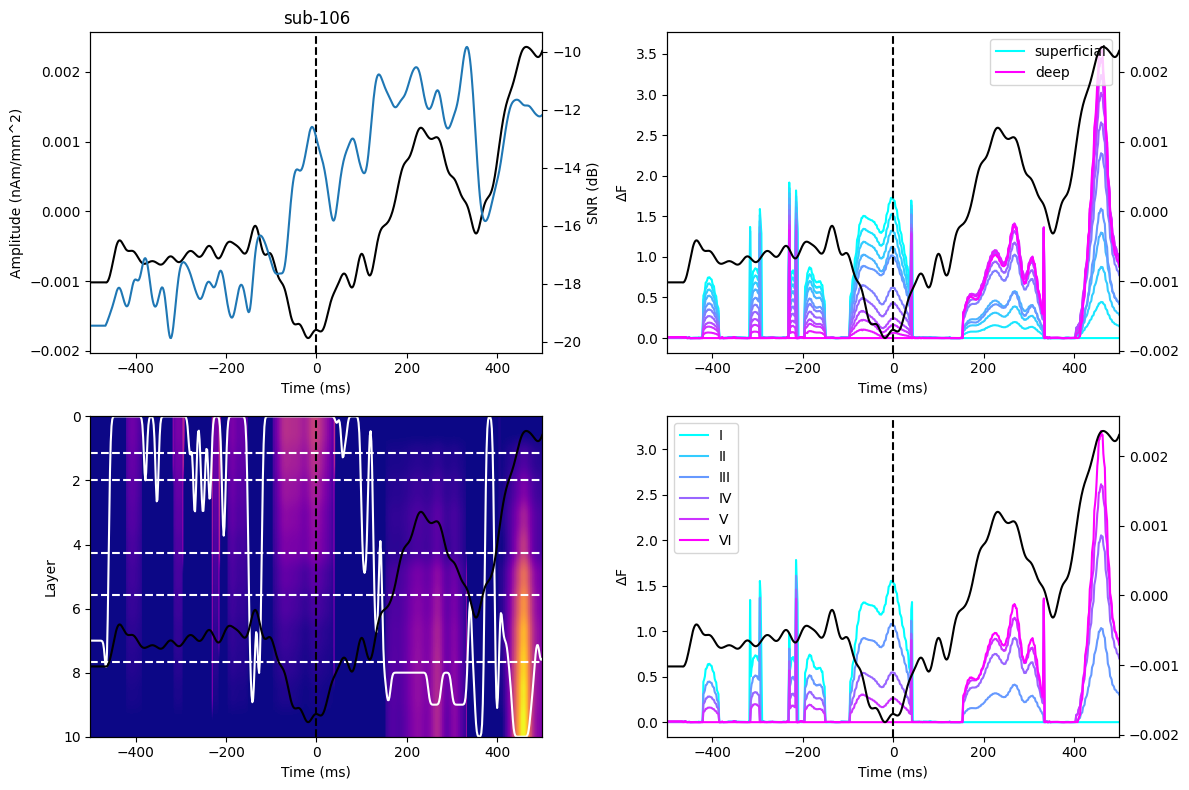

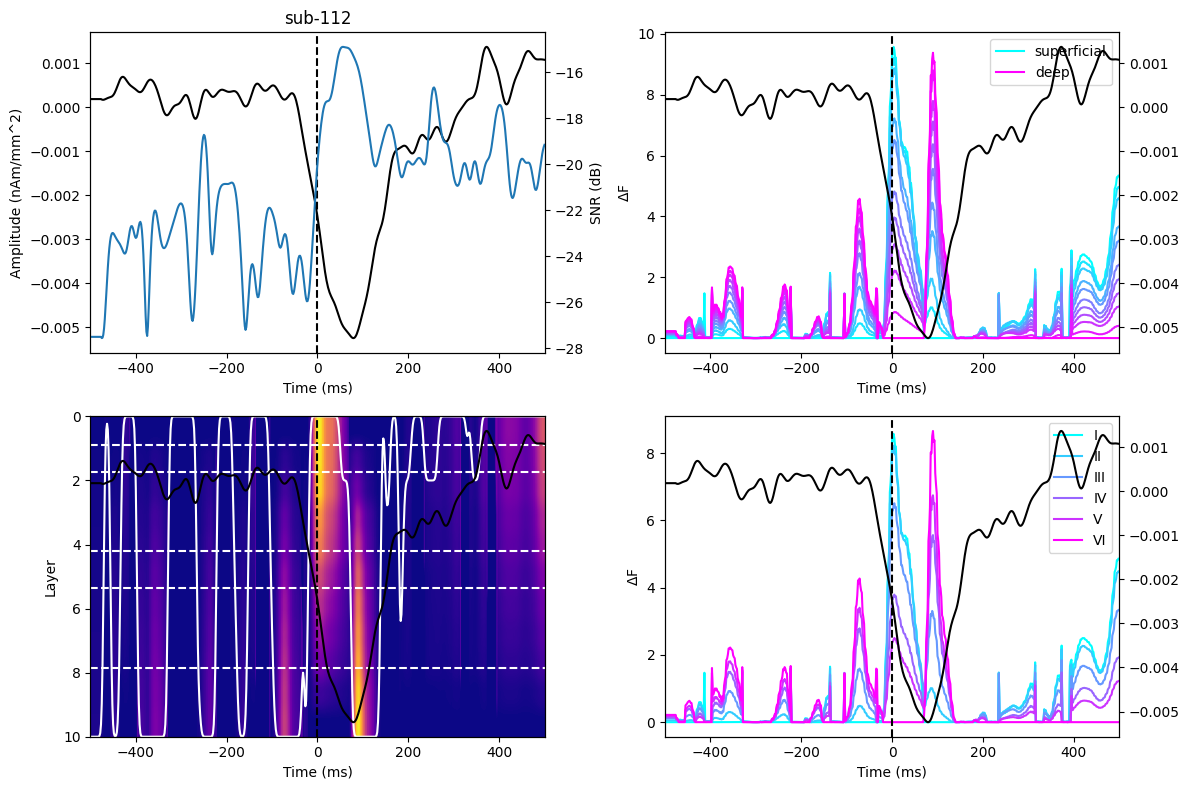

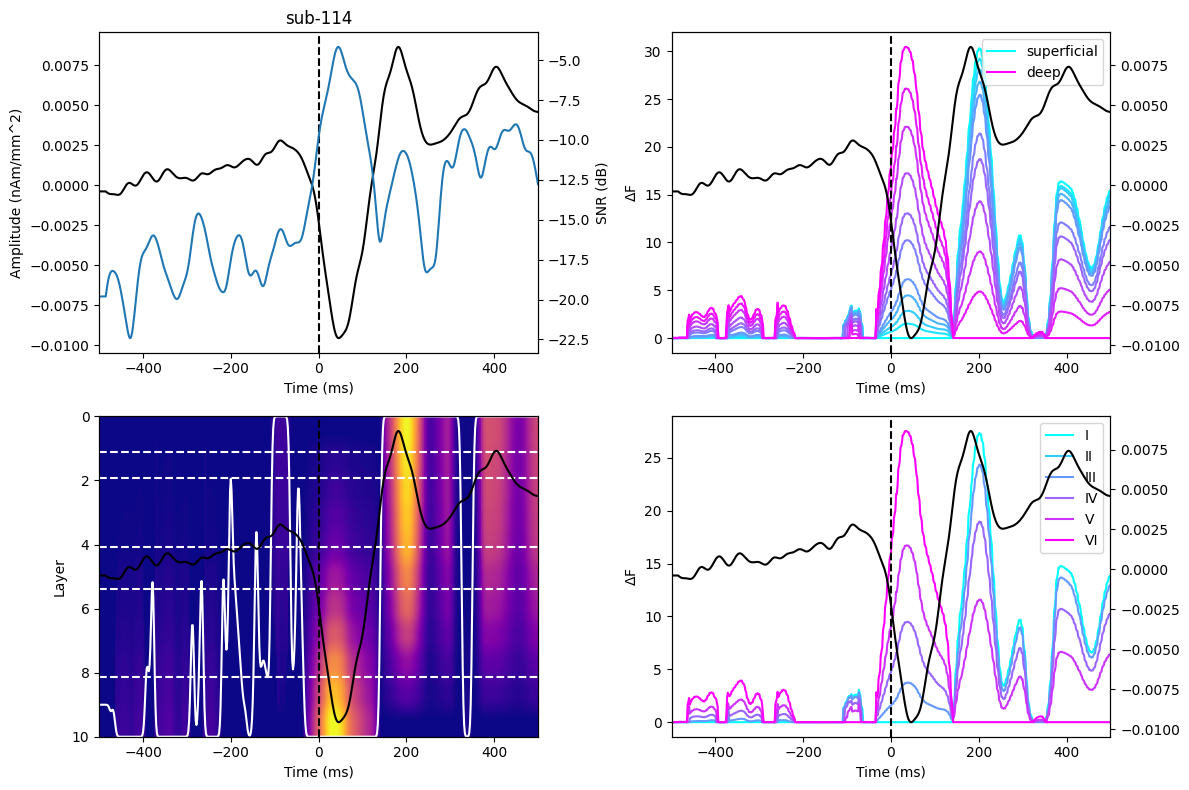

In [7]:
aligned_subjects_m_snrs = []
aligned_subjects_m_prior_ts = []
aligned_subjects_m_F_diff = []
aligned_subjects_m_layer_F_diff = []

for s_idx, subject in enumerate(subjects):
    if s_idx<aligned_snrs.shape[0]:
        subj_m_snrs = aligned_snrs[s_idx,:]
        subj_m_prior_ts = aligned_prior_ts[s_idx,:]
        subj_m_F_diff = aligned_F_diff[s_idx,:,:]
        subj_m_layer_F_diff = aligned_layer_F_diff[s_idx,:,:]
        subj_m_bb_boundaries = all_bb_boundaries[s_idx,:]

        aligned_subjects_m_snrs.append(subj_m_snrs)
        aligned_subjects_m_prior_ts.append(subj_m_prior_ts)
        aligned_subjects_m_F_diff.append(subj_m_F_diff)
        aligned_subjects_m_layer_F_diff.append(subj_m_layer_F_diff)

        col_r = plt.cm.cool(np.linspace(0,1, num=n_layers))
        fig=plt.figure(figsize=(12,8))

        ax=plt.subplot(2,2,1)
        ax.plot(ts_time,subj_m_prior_ts,'k')
        ax.axvline(x=0, color='k', linestyle='--')
        ax2=ax.twinx()
        ax2.plot(sensor_time, subj_m_snrs)
        ax.set_ylabel('Amplitude (nAm/mm^2)')
        ax2.set_ylabel('SNR (dB)')
        ax.set_xlabel('Time (ms)')
        ax.set_title(subject)
        ax.set_xlim(time_lims)

        # Plot relative free energy time series
        ax=plt.subplot(2,2,2)
        for l in range(n_layers):
            if l==0:
                ax.plot(woi_win, subj_m_F_diff[l,:], label='superficial', color=col_r[l,:])
            elif l==n_layers-1:
                ax.plot(woi_win, subj_m_F_diff[l,:], label='deep', color=col_r[l,:])
            else:
                ax.plot(woi_win, subj_m_F_diff[l,:], color=col_r[l,:])
        ax.axvline(x=0, color='k', linestyle='--')
        plt.legend(loc='upper right')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel(r'$\Delta$F')
        ax.set_xlim(time_lims)

        ax=plt.subplot(2,2,3)
        h=ax.imshow(subj_m_F_diff,aspect='auto', extent=[woi_win[0], woi_win[-1], n_layers-1,0],cmap='plasma',origin='upper')
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Layer')
        peak_layer=gaussian_filter1d(np.argmax(subj_m_F_diff,axis=0).astype(float), 2)
        ax.plot(woi_win, peak_layer, 'w')
        ax.axvline(x=0, color='k', linestyle='--')
        for i in range(len(subj_m_bb_boundaries)-1):
            ax.axhline(y=subj_m_bb_boundaries[i],color='w',linestyle='--')        
        # col_r=plt.colorbar(h)
        # col_r.set_label(r'$\Delta$F')
        # divider = make_axes_locatable(ax)
        # cax = divider.append_axes("right", size="5%", pad=0.1)
        # cbar = fig.colorbar(h, cax=cax, label=r'$\Delta$F')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax2.set_yticks([])

        ax=plt.subplot(2,2,4)
        col_l = plt.cm.cool(np.linspace(0,1, num=6))
        l_labels=['I','II','III','IV','V','VI']
        for i in range(6):
            ax.plot(woi_win, subj_m_layer_F_diff[i,:],label=l_labels[i],color=col_l[i])
        ax.axvline(x=0, color='k', linestyle='--')
        plt.legend()
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel(r'$\Delta$F')
        ax2=ax.twinx()
        ax2.plot(ts_time,subj_m_prior_ts,'k')
        ax.set_xlim(time_lims)

        plt.tight_layout()

aligned_subjects_m_snrs = np.array(aligned_subjects_m_snrs)
aligned_subjects_m_prior_ts = np.array(aligned_subjects_m_prior_ts)
aligned_subjects_m_F_diff = np.array(aligned_subjects_m_F_diff)
aligned_subjects_m_layer_F_diff = np.array(aligned_subjects_m_layer_F_diff)


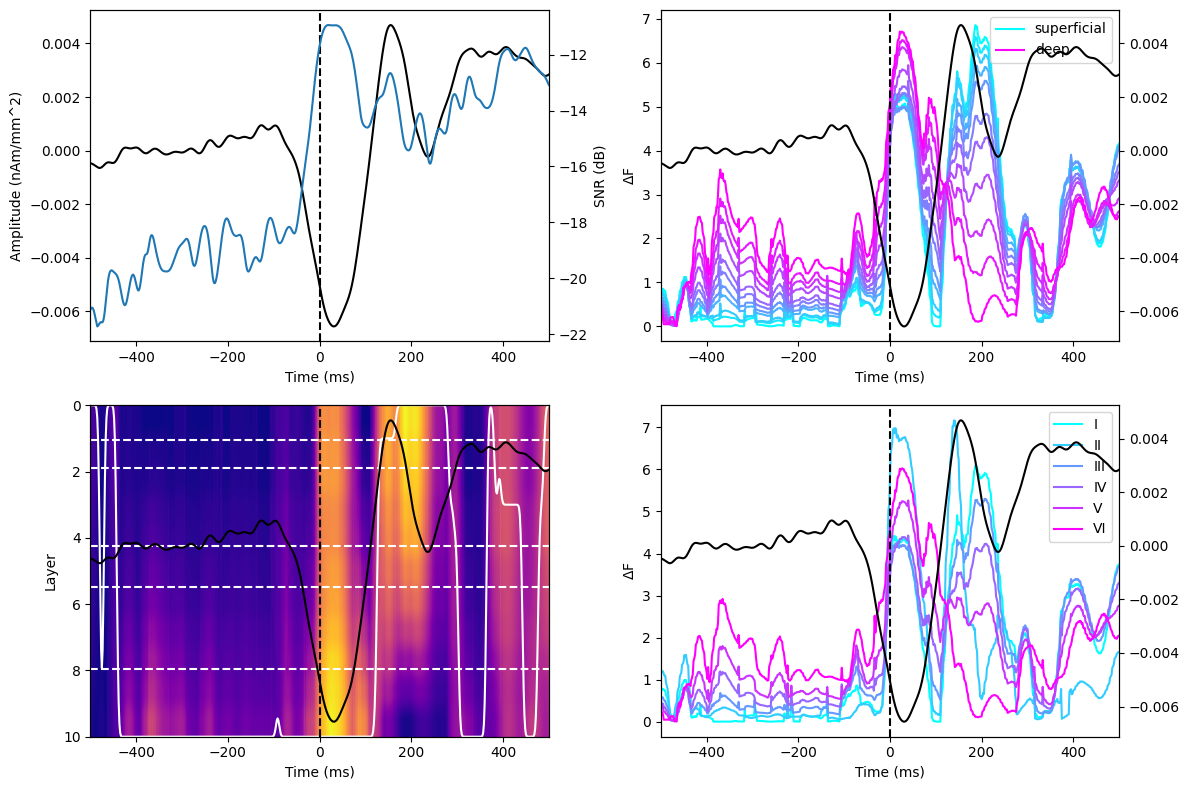

In [8]:
m_snrs=np.mean(aligned_subjects_m_snrs,axis=0)
m_prior_ts=np.mean(aligned_subjects_m_prior_ts,axis=0)
m_F_diff=np.mean(aligned_subjects_m_F_diff,axis=0)
m_layer_F_diff=np.nanmean(aligned_subjects_m_layer_F_diff,axis=0)
m_bb_boundaries=np.mean(subjects_m_bb_boundaries,axis=0)

col_r = plt.cm.cool(np.linspace(0,1, num=n_layers))
fig=plt.figure(figsize=(12,8))

ax=plt.subplot(2,2,1)
ax.plot(ts_time,m_prior_ts,'k')
ax.axvline(x=0, color='k', linestyle='--')
ax2=ax.twinx()
ax2.plot(sensor_time, m_snrs)
ax.set_ylabel('Amplitude (nAm/mm^2)')
ax2.set_ylabel('SNR (dB)')
ax.set_xlabel('Time (ms)')
ax.set_xlim(time_lims)

# Plot relative free energy time series
ax=plt.subplot(2,2,2)
for l in range(n_layers):
    if l==0:
        ax.plot(woi_win, m_F_diff[l,:], label='superficial', color=col_r[l,:])
    elif l==n_layers-1:
        ax.plot(woi_win, m_F_diff[l,:], label='deep', color=col_r[l,:])
    else:
        ax.plot(woi_win, m_F_diff[l,:], color=col_r[l,:])
ax.axvline(x=0, color='k', linestyle='--')
plt.legend(loc='upper right')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax.set_xlabel('Time (ms)')
ax.set_ylabel(r'$\Delta$F')
ax.set_xlim(time_lims)

ax=plt.subplot(2,2,3)
h=ax.imshow(m_F_diff,aspect='auto', extent=[woi_win[0], woi_win[-1], n_layers-1,0],cmap='plasma',origin='upper')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Layer')
peak_layer=gaussian_filter1d(np.argmax(m_F_diff,axis=0).astype(float), 2)
ax.plot(woi_win, peak_layer, 'w')
ax.axvline(x=0, color='k', linestyle='--')
for i in range(len(m_bb_boundaries)-1):
    ax.axhline(y=m_bb_boundaries[i],color='w',linestyle='--')        
# col_r=plt.colorbar(h)
# col_r.set_label(r'$\Delta$F')
# divider = make_axes_locatable(ax)
# cax = divider.append_axes("right", size="5%", pad=0.1)
# cbar = fig.colorbar(h, cax=cax, label=r'$\Delta$F')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax2.set_yticks([])

ax=plt.subplot(2,2,4)
col_l = plt.cm.cool(np.linspace(0,1, num=6))
l_labels=['I','II','III','IV','V','VI']
for i in range(6):
    ax.plot(woi_win, m_layer_F_diff[i,:],label=l_labels[i],color=col_l[i])
ax.axvline(x=0, color='k', linestyle='--')
plt.legend()
ax.set_xlabel('Time (ms)')
ax.set_ylabel(r'$\Delta$F')
ax2=ax.twinx()
ax2.plot(ts_time,m_prior_ts,'k')
ax.set_xlim(time_lims)


plt.tight_layout()
#plt.savefig('./figures/btn_trial_epoch_aligned_mean_rel_to_worst.pdf')